# Discrete-Adjoint PDE Control
### One gradient, independent of the number of controls

**Learning goal:** Formulate a bounded PDE-constrained optimization problem, derive and implement its discrete adjoint, verify the gradient using directional derivatives, and use L-BFGS-B to control a fixed-grid convection-diffusion state.

**Time:** 60-90 minutes. Python, NumPy, SciPy, Matplotlib. The spatial grid is fixed at N = 200; this is not a grid-convergence exercise.

**Core idea:** A direct sensitivity method would solve one linearized state equation for every design variable. The adjoint reorganizes the chain rule so the full scalar-objective gradient requires one transpose solve, regardless of the number of controls.

**Success targets:** adjoint and direct-sensitivity gradients agree to relative norm error below 1e-10; a centered directional-derivative check reaches relative error below 1e-6; the optimizer reports success and reduces the objective by at least 90%; and all bounds and algebraic residual checks pass.

Derive the signs before coding; a plausible optimized plot does not validate an adjoint.

## 1. Governing model and reference solution

Solve the steady one-dimensional convection-diffusion equation
$$-\nu u''(x)+a u'(x)=s(x;p),\qquad x\in(0,1),\qquad u(0)=u(1)=0,$$
with $\nu=0.01$, $a=1$, and N = 200 interior nodes. Use centered second diffusion and first-order upwind convection for positive a:
$$-\nu\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}+a\frac{u_i-u_{i-1}}{h}=s_i.$$
This produces a nonsymmetric sparse system
$$Au=Bp,$$
where p contains M = 12 actuator amplitudes. Let column j of B be a Gaussian
$$B_{ij}=\exp\left[-\frac{(x_i-c_j)^2}{2\sigma^2}\right],$$
with equally spaced centers $c_j$ from 0.08 to 0.92 and $\sigma=0.045$. Use bounds $0\le p_j\le20$.

Use a target that cannot be represented exactly by the coarse actuator basis:
$$u_d(x)=0.8\exp[-((x-0.68)/0.10)^2]+0.22\exp[-((x-0.30)/0.06)^2].$$

Factor A and $A^T$ once. Do not form an inverse. Confirm A is nonsymmetric, has positive diagonal, and has at most 3N nonzeros.

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import splu
from scipy.optimize import minimize

N = 200
M = 12
NU = 0.01
ADV = 1.0
SIGMA = 0.045
ALPHA = 2.0e-5
BETA = 5.0e-4
P_BOUNDS = (0.0, 20.0)

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 110
print("SciPy version:", scipy.__version__)
print("NumPy version:", np.__version__)


SciPy version: 1.18.1
NumPy version: 2.5.2


## 2. Discretization and conditions

Minimize
$$J(u,p)=\frac{h}{2}\|u-u_d\|_2^2+\frac{\alpha}{2}\|p\|_2^2+\frac{\beta}{2}\|Dp\|_2^2,$$
where D is the first-difference matrix on controls: $(Dp)_j=p_{j+1}-p_j$. The first term tracks the desired state, alpha limits control effort, and beta discourages actuator-to-actuator roughness.

Implement a state solve and an objective decomposition returning tracking, effort, smoothness, and total terms. Use the same h weighting in the objective and adjoint. Omitting it changes the balance between tracking and regularization.

Start from $p_0=2\mathbf{1}$. Cache or reuse the factorizations, but do not cache states across different p values unless the key is exact and the implementation remains transparent.

In [2]:
def build_problem(n=N, m=M):
    """Return x, h, sparse A, dense B, D, target, and LU factors."""
    h = 1.0 / (n + 1)
    x = np.arange(1, n + 1) * h

    sub = -NU / h**2 - ADV / h
    main = 2.0 * NU / h**2 + ADV / h
    sup = -NU / h**2
    A = diags(
        [sub * np.ones(n - 1), main * np.ones(n), sup * np.ones(n - 1)],
        offsets=[-1, 0, 1],
        format="csc",
    )
    luA = splu(A)
    luAT = splu(A.transpose().tocsc())

    centers = np.linspace(0.08, 0.92, m)
    B = np.exp(-((x[:, None] - centers[None, :]) ** 2) / (2.0 * SIGMA**2))

    D = np.zeros((m - 1, m))
    for j in range(m - 1):
        D[j, j] = -1.0
        D[j, j + 1] = 1.0

    target = 0.8 * np.exp(-(((x - 0.68) / 0.10) ** 2)) + 0.22 * np.exp(
        -(((x - 0.30) / 0.06) ** 2)
    )

    return {
        "n": n,
        "m": m,
        "x": x,
        "h": h,
        "A": A,
        "B": B,
        "D": D,
        "centers": centers,
        "target": target,
        "luA": luA,
        "luAT": luAT,
    }


def solve_state(p, problem):
    rhs = problem["B"] @ p
    return problem["luA"].solve(rhs)


def objective_terms(u, p, problem):
    h = problem["h"]
    target = problem["target"]
    D = problem["D"]
    tracking = 0.5 * h * np.sum((u - target) ** 2)
    effort = 0.5 * ALPHA * np.sum(p**2)
    smoothness = 0.5 * BETA * np.sum((D @ p) ** 2)
    total = tracking + effort + smoothness
    return {"tracking": tracking, "effort": effort, "smoothness": smoothness, "total": total}


## 3. Error measures and expected behavior

Use the residual $R(u,p)=Bp-Au=0$ and Lagrangian
$$\mathcal L(u,p)=J(u,p)+\lambda^T(Bp-Au).$$
Stationarity with respect to u gives
$$A^T\lambda=h(u-u_d).$$
The reduced gradient is
$$\nabla_p\hat J=B^T\lambda+\alpha p+\beta D^TDp.$$

Derive these equations yourself and check the sign by differentiating $u=A^{-1}Bp$. Implement one routine that returns objective and gradient for SciPy. Count state and adjoint solves explicitly. A scalar objective requires one state and one adjoint solve per new p, not M state solves.

For an independent direct-sensitivity reference, solve $AS=B$ for all M columns and compute
$$\nabla_p\hat J=S^T h(u-u_d)+\alpha p+\beta D^TDp.$$
Use this only for verification at one p, not inside the optimizer.

In [3]:
_last_eval = {}


def objective_and_adjoint_gradient(p, problem, counters=None):
    """Return reduced objective and exact discrete-adjoint gradient."""
    p = np.asarray(p, dtype=float)
    u = solve_state(p, problem)
    if counters is not None:
        counters["state"] += 1

    terms = objective_terms(u, p, problem)

    h = problem["h"]
    target = problem["target"]
    D = problem["D"]
    lam = problem["luAT"].solve(h * (u - target))
    if counters is not None:
        counters["adjoint"] += 1

    grad = problem["B"].T @ lam + ALPHA * p + BETA * (D.T @ (D @ p))

    _last_eval["p"] = p.copy()
    _last_eval["u"] = u
    _last_eval["lam"] = lam
    _last_eval["terms"] = terms
    _last_eval["grad"] = grad

    return terms["total"], grad


def direct_sensitivity_gradient(p, problem):
    """Solve A S = B and form the independent reference gradient."""
    p = np.asarray(p, dtype=float)
    u = solve_state(p, problem)
    S = problem["luA"].solve(problem["B"])

    h = problem["h"]
    target = problem["target"]
    D = problem["D"]
    return S.T @ (h * (u - target)) + ALPHA * p + BETA * (D.T @ (D @ p))


## 4. Results and convergence

At a seeded interior test point $p_{test}\in[3,7]^M$, draw a seeded unit direction d. Compare:

1. The full adjoint gradient with the direct-sensitivity gradient.
2. The scalar adjoint projection $g^Td$ with centered finite differences
$$\phi_\epsilon=\frac{\hat J(p+\epsilon d)-\hat J(p-\epsilon d)}{2\epsilon}$$
for $\epsilon=10^{-1},10^{-2},\ldots,10^{-8}$.

Plot relative directional error
$$e(\epsilon)=\frac{|\phi_\epsilon-g^Td|}{\max(1,|g^Td|)}.$$
Expect a truncation-to-roundoff curve, not monotonic decrease to the smallest epsilon. Report the best epsilon and error. Keep the test point away from active bounds so this verifies the unconstrained reduced gradient.

Also verify the primal and adjoint relative residuals independently. Do not use a finite-difference gradient as the optimization gradient.

In [4]:
problem = build_problem()

rng = np.random.default_rng(20261012)
p_test = rng.uniform(3.0, 7.0, M)
d = rng.normal(size=M)
d = d / np.linalg.norm(d)

total_test, grad_adjoint = objective_and_adjoint_gradient(p_test, problem)
grad_direct = direct_sensitivity_gradient(p_test, problem)
grad_rel_error = np.linalg.norm(grad_adjoint - grad_direct) / np.linalg.norm(grad_direct)

u_test = _last_eval["u"]
lam_test = _last_eval["lam"]
primal_rhs = problem["B"] @ p_test
primal_residual = np.linalg.norm(problem["A"] @ u_test - primal_rhs) / np.linalg.norm(primal_rhs)
adjoint_rhs = problem["h"] * (u_test - problem["target"])
adjoint_residual = np.linalg.norm(problem["A"].T @ lam_test - adjoint_rhs) / np.linalg.norm(adjoint_rhs)

g_dot_d = grad_adjoint @ d
exponents = np.arange(1, 9)
epsilons = 10.0 ** (-exponents)
directional_errors = np.empty_like(epsilons)
for i, eps in enumerate(epsilons):
    j_plus, _ = objective_and_adjoint_gradient(p_test + eps * d, problem)
    j_minus, _ = objective_and_adjoint_gradient(p_test - eps * d, problem)
    phi = (j_plus - j_minus) / (2.0 * eps)
    directional_errors[i] = abs(phi - g_dot_d) / max(1.0, abs(g_dot_d))

best_index = int(np.argmin(directional_errors))
best_epsilon = epsilons[best_index]
best_directional_error = directional_errors[best_index]

print(f"Adjoint vs. direct-sensitivity relative gradient error: {grad_rel_error:.3e}")
print(f"Primal relative residual:  {primal_residual:.3e}")
print(f"Adjoint relative residual: {adjoint_residual:.3e}")
print(f"Best directional error: {best_directional_error:.3e} at epsilon={best_epsilon:.1e}")


Adjoint vs. direct-sensitivity relative gradient error: 1.241e-14
Primal relative residual:  4.899e-14
Adjoint relative residual: 6.433e-14
Best directional error: 2.648e-14 at epsilon=1.0e-01


## 5. Solution and diagnostic plots

Run `scipy.optimize.minimize` with method `L-BFGS-B`, analytic `jac`, twelve bounds [0,20], `gtol=1e-8`, `ftol=1e-12`, and `maxiter=200`. Record objective components and projected-gradient information in a callback without recomputing a state solely for plotting.

Required diagnostics:

1. Initial state, target, and optimized state versus x.
2. Initial and optimized actuator amplitudes versus actuator center.
3. Objective, tracking, effort, and smoothness versus accepted iteration on a semilog axis.
4. Gradient-check error versus epsilon.

Report optimizer status/message, iterations, function/gradient calls, counted state/adjoint solves, objective reduction, active lower/upper bounds, and final state/adjoint residuals. Distinguish the raw gradient from the projected gradient when bounds are active.

Optimizer status: 0 - CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Iterations: 25 | function evals: 27
State solves: 29 | adjoint solves: 29
Objective reduction: 97.92%
Active lower bounds: 6 | active upper bounds: 0
Final primal residual: 4.257e-14 | final adjoint residual: 1.061e-14
Final raw gradient norm: 7.555e-03 | final projected gradient norm: 7.774e-08


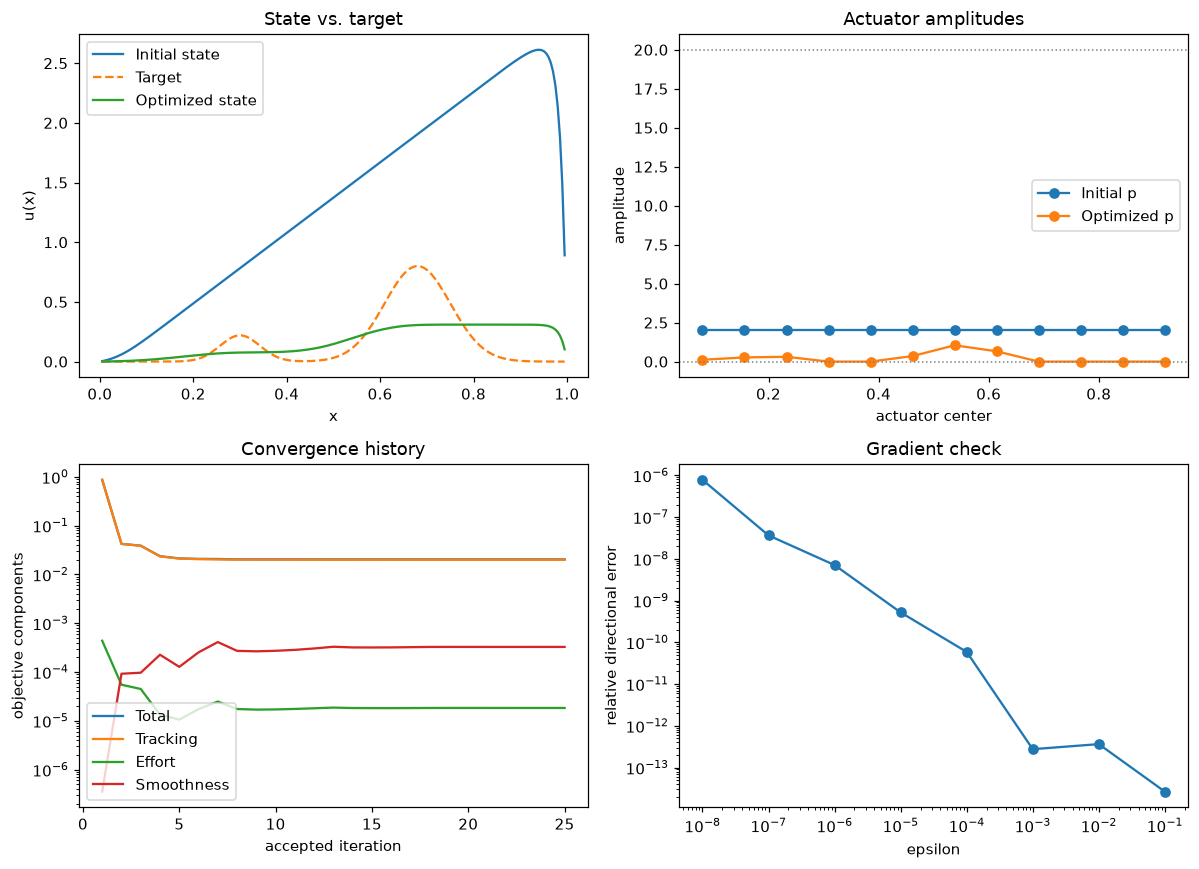

In [5]:
counters = {"state": 0, "adjoint": 0}
p0 = 2.0 * np.ones(M)

history = {
    "iteration": [],
    "total": [],
    "tracking": [],
    "effort": [],
    "smoothness": [],
    "grad_norm": [],
    "proj_grad_norm": [],
}


def fun_and_grad(p):
    return objective_and_adjoint_gradient(p, problem, counters=counters)


def callback(p):
    # Reuse the cache from the last fun_and_grad evaluation rather than re-solving.
    terms = _last_eval["terms"]
    grad = _last_eval["grad"]
    at_lower = p <= P_BOUNDS[0] + 1e-10
    at_upper = p >= P_BOUNDS[1] - 1e-10
    proj_grad = grad.copy()
    proj_grad[at_lower & (grad > 0.0)] = 0.0
    proj_grad[at_upper & (grad < 0.0)] = 0.0

    history["iteration"].append(len(history["iteration"]) + 1)
    history["total"].append(terms["total"])
    history["tracking"].append(terms["tracking"])
    history["effort"].append(terms["effort"])
    history["smoothness"].append(terms["smoothness"])
    history["grad_norm"].append(np.linalg.norm(grad))
    history["proj_grad_norm"].append(np.linalg.norm(proj_grad))


initial_total, initial_grad = fun_and_grad(p0)
initial_terms = dict(_last_eval["terms"])
initial_u = _last_eval["u"].copy()

result = minimize(
    fun_and_grad,
    p0,
    jac=True,
    method="L-BFGS-B",
    bounds=[P_BOUNDS] * M,
    callback=callback,
    options={"gtol": 1e-8, "ftol": 1e-12, "maxiter": 200},
)

p_opt = result.x
final_total, final_grad = fun_and_grad(p_opt)
final_terms = dict(_last_eval["terms"])
u_opt = _last_eval["u"].copy()
lam_opt = _last_eval["lam"].copy()

lower_active = np.isclose(p_opt, P_BOUNDS[0], atol=1e-10)
upper_active = np.isclose(p_opt, P_BOUNDS[1], atol=1e-10)

primal_residual_final = np.linalg.norm(
    problem["A"] @ u_opt - problem["B"] @ p_opt
) / np.linalg.norm(problem["B"] @ p_opt)
adjoint_rhs_final = problem["h"] * (u_opt - problem["target"])
adjoint_residual_final = np.linalg.norm(
    problem["A"].T @ lam_opt - adjoint_rhs_final
) / np.linalg.norm(adjoint_rhs_final)

objective_reduction = 1.0 - final_total / initial_total

print("Optimizer status:", result.status, "-", result.message)
print("Iterations:", result.nit, "| function evals:", result.nfev)
print("State solves:", counters["state"], "| adjoint solves:", counters["adjoint"])
print(f"Objective reduction: {objective_reduction * 100:.2f}%")
print("Active lower bounds:", int(lower_active.sum()), "| active upper bounds:", int(upper_active.sum()))
print(f"Final primal residual: {primal_residual_final:.3e} | final adjoint residual: {adjoint_residual_final:.3e}")
print(f"Final raw gradient norm: {history['grad_norm'][-1]:.3e} | final projected gradient norm: {history['proj_grad_norm'][-1]:.3e}")

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(problem["x"], initial_u, label="Initial state")
axes[0, 0].plot(problem["x"], problem["target"], "--", label="Target")
axes[0, 0].plot(problem["x"], u_opt, label="Optimized state")
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("u(x)")
axes[0, 0].set_title("State vs. target")
axes[0, 0].legend()

axes[0, 1].plot(problem["centers"], p0, "o-", label="Initial p")
axes[0, 1].plot(problem["centers"], p_opt, "o-", label="Optimized p")
axes[0, 1].axhline(P_BOUNDS[0], color="gray", linestyle=":", linewidth=1)
axes[0, 1].axhline(P_BOUNDS[1], color="gray", linestyle=":", linewidth=1)
axes[0, 1].set_xlabel("actuator center")
axes[0, 1].set_ylabel("amplitude")
axes[0, 1].set_title("Actuator amplitudes")
axes[0, 1].legend()

axes[1, 0].semilogy(history["iteration"], history["total"], label="Total")
axes[1, 0].semilogy(history["iteration"], history["tracking"], label="Tracking")
axes[1, 0].semilogy(history["iteration"], history["effort"], label="Effort")
axes[1, 0].semilogy(history["iteration"], history["smoothness"], label="Smoothness")
axes[1, 0].set_xlabel("accepted iteration")
axes[1, 0].set_ylabel("objective components")
axes[1, 0].set_title("Convergence history")
axes[1, 0].legend()

axes[1, 1].loglog(epsilons, directional_errors, "o-")
axes[1, 1].set_xlabel("epsilon")
axes[1, 1].set_ylabel("relative directional error")
axes[1, 1].set_title("Gradient check")

fig.tight_layout()
plt.show()


## 6. Automatic checks

Assert:

- Shapes are A(N,N), B(N,M), D(M-1,M); A and B entries are finite; A has at most 3N nonzeros and is nonsymmetric.
- Every state and adjoint relative residual is below 1e-11.
- Adjoint and direct-sensitivity gradients agree to relative norm error below 1e-10 at the seeded interior test point.
- The best centered directional-derivative error is below 1e-6, and its epsilon is reported rather than assumed.
- The optimizer reports success; all p values satisfy bounds within 1e-10; the final objective is below 10% of the initial objective.
- Recomputed final objective components sum to the reported total within 1e-12 relative error.
- The analytic gradient uses exactly one adjoint solve per new objective/gradient evaluation; no loop over controls appears in the adjoint routine.

Do not require a particular active-set pattern or iteration count. If the 90% reduction check fails, diagnose signs, h weighting, target construction, and optimizer bookkeeping before changing the problem.

In [6]:
import inspect

assert problem["A"].shape == (N, N)
assert problem["B"].shape == (N, M)
assert problem["D"].shape == (M - 1, M)
assert np.all(np.isfinite(problem["A"].data))
assert np.all(np.isfinite(problem["B"]))
assert problem["A"].nnz <= 3 * N
assert not np.allclose(problem["A"].toarray(), problem["A"].toarray().T)
assert np.all(problem["A"].diagonal() > 0.0)

assert primal_residual < 1e-11
assert adjoint_residual < 1e-11
assert primal_residual_final < 1e-11
assert adjoint_residual_final < 1e-11

assert grad_rel_error < 1e-10
assert best_directional_error < 1e-6

assert result.success
assert np.all(p_opt >= P_BOUNDS[0] - 1e-10)
assert np.all(p_opt <= P_BOUNDS[1] + 1e-10)
assert final_total < 0.10 * initial_total

recomputed_total = final_terms["tracking"] + final_terms["effort"] + final_terms["smoothness"]
assert abs(recomputed_total - final_terms["total"]) <= 1e-12 * max(1.0, abs(final_terms["total"]))

adjoint_source = inspect.getsource(objective_and_adjoint_gradient)
assert "for " not in adjoint_source and "while " not in adjoint_source

print("All automatic success checks passed.")


All automatic success checks passed.


## 7. Discussion and next steps

Answer briefly:

1. Why does the adjoint cost not grow linearly with the number of controls for one scalar objective?
2. Why is the transpose system essential for this upwind, nonsymmetric operator?
3. What does beta change in the control field and tracking error?
4. How do active bounds alter the correct optimality condition?
5. Which pieces generalize directly to a nonlinear CFD residual $R(U,p)=0$, and which require linearization at every design iterate?

**Stretch goal (15-25 minutes):** Repeat with M = 48 actuators while keeping N fixed. Compare direct-sensitivity and adjoint solve counts and wall times for one gradient. Do not change the PDE grid. Alternatively, add one scalar equality constraint on total control and solve with SLSQP using its analytic gradient.

### References

- **Dedicated project reference:** Michael B. Giles and Niles A. Pierce, "An Introduction to the Adjoint Approach to Design," *Flow, Turbulence and Combustion* 65, 393-415, 2000. DOI: 10.1023/A:1011430410075. [Author PDF](https://people.maths.ox.ac.uk/gilesm/files/ftc00.pdf). Focus on the Lagrangian derivation, cost scaling, and discrete-versus-continuous distinction.
- **Optimizer reference:** [SciPy L-BFGS-B documentation](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html). Record version, stopping tolerances, bounds, and final status.
- **Paper to read:** Christian Psenica, Lean Fang, Seth Zoppelt, Mark Leader, and Ping He, "A Modular Conjugate Heat Transfer Optimization Framework for Thermal Management of Electric Aircraft," *International Journal of Heat and Mass Transfer* 259, 128345, 2026. DOI: 10.1016/j.ijheatmasstransfer.2026.128345. [NASA Glenn accepted manuscript and metadata](https://ntrs.nasa.gov/citations/20260000381). Read for modular multiphysics coupling, discrete-adjoint gradients, interface consistency, constraints, and fine/unsteady confirmation of optimized designs.

### Topic ledger

| Date / record | Primary objective | Status |
|---|---|---|
| Older assignments, dates unavailable | Grid convergence and errors | User reported five repetitive assignments; individual records unavailable |
| 2026-10-05 | Grid convergence and discretization uncertainty | Inspected |
| 2026-10-06 corrected | Fixed-mesh advection, CFL, conservation, positivity, TV | Inspected |
| 2026-10-07 | Krylov methods and line-block preconditioning | Inspected |
| 2026-10-08 | Data layout, cache behavior, and kernel throughput | Inspected |
| 2026-10-09 | Nonlinear natural-circulation thermal-fluid modeling | Inspected |
| 2026-10-12 | Discrete-adjoint PDE-constrained optimization | This assignment |

Only five preceding distinct projects are recoverable, so a complete seven-project audit remains unavailable. The reported older repetitions remain excluded. This is assignment 4 of the ten-assignment exclusion established October 6; six remain after today. Planned next primary objectives: multiphysics coupling, high-order reconstruction, parallel algorithms, then time integration. No grid-refinement, observed-order, Richardson, or GCI task appears here.